# EquityAgent: An Autonomous Agentic Workflow for Investment Research

**GitHub repository:** https://github.com/nicole-rowley-msaai/MS_AAI_520_NLP_GenAI_Final (branch `agent`)

MS in Applied AI, University of San Diego. AAI-520: NLP and Generative AI,
final project.

**Team:** Data lead, NLP lead, Agent lead (Nicole Rowley), Evaluation lead.

EquityAgent researches a stock ticker end to end: it plans the research,
calls market, macro, news and SEC-filing tools, runs a five-step prompt
chain over the news, routes each task to a specialist, writes a brief,
grades and revises it, reflects on the run, and stores lessons that change
the next run's plan. Demo tickers: NVDA, JPM, XOM.

| Part | Contents | Assignment heading |
|---|---|---|
| A | Data check, Kaggle news EDA, classifier evaluation | Agent Functions and Capabilities |
| B | One agent run with every step printed | Agent Design and Workflows |
| C | Baseline comparison, memory ablation, limitations | Evaluation and Iteration |

**Models.** Planner, router and news chain: `gpt-6-luna`. Writer and
optimizer: `claude-sonnet-5`. Evaluator: `gpt-6-sol` (a different family
from the writer, so the draft is not graded by the model that wrote it).
Embeddings: `all-MiniLM-L6-v2`.


## Setup

In [1]:
# --- Colab setup -----------------------------------------------------
import os
import sys

from google.colab import drive, userdata

os.chdir("/content")
drive.mount("/content/drive")

REPO = "/content/drive/MyDrive/equity-agent"
REPO_URL = (
    f"https://{userdata.get('GITHUB_TOKEN')}@github.com/"
    "nicole-rowley-msaai/MS_AAI_520_NLP_GenAI_Final.git"
)
if os.path.isdir(os.path.join(REPO, ".git")):
    !git -C {REPO} pull -q
else:
    !git clone -q --branch agent {REPO_URL} {REPO}
%cd {REPO}
sys.path.insert(0, REPO)

SKIP = "google-adk\|dependency resolver"
!pip install -q -r requirements.txt 2>&1 | grep -v "{SKIP}"

SECRET_KEYS = [
    "OPENAI_API_KEY",
    "ANTHROPIC_API_KEY",
    "FRED_API_KEY",
    "NEWSAPI_KEY",
    "EDGAR_USER_AGENT",
    "KAGGLE_USERNAME",
    "KAGGLE_KEY",
]
loaded = []
for key in SECRET_KEYS:
    try:
        os.environ[key] = userdata.get(key)
        loaded.append(key)
    except Exception:
        print(f"Missing secret: {key}")
print("Loaded:", loaded)


<>:22: SyntaxWarning: invalid escape sequence '\|'
<>:22: SyntaxWarning: invalid escape sequence '\|'
/tmp/ipykernel_7265/1358920658.py:22: SyntaxWarning: invalid escape sequence '\|'
  SKIP = "google-adk\|dependency resolver"


Mounted at /content/drive
/content/drive/MyDrive/equity-agent
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.9/108.9 kB 6.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 186.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 147.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 149.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 40.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 173.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 119.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 32.1 M

In [2]:
import logging
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", module="huggingface_hub")

from src import display as show  # noqa: E402
from src.config import TICKERS  # noqa: E402
from src.evaluation import (  # noqa: E402
    baseline_brief,
    quick_smoke,
    score_against_findings,
    tool_success_rate,
    unsupported_figures,
)
from src.graph import run_agent  # noqa: E402
from src.memory import store  # noqa: E402
from src.tools import safe_call  # noqa: E402
from src.tools.retrieval import index_filings  # noqa: E402

pd.set_option("display.max_colwidth", 120)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

# Part A. Data and NLP

## Agent Functions and Capabilities

The agent's tools and the news prompt chain are built and tested before
the agent uses them. This part checks each data source (yfinance, FRED,
NewsAPI, SEC EDGAR), explores the Kaggle financial-news dataset used to
benchmark the sentiment classifier, and compares the LLM classifier with
a keyword baseline. Every tool call goes through `safe_call`, so a failed
API shows as `ok=False` instead of stopping the notebook.


## A1. Data check: does every tool return data?

Each call goes through `safe_call`, so a failed API shows as `ok=False`
instead of stopping the notebook.

In [3]:
from src.tools.filings import extract_sections, get_latest_10k
from src.tools.macro import get_macro_snapshot
from src.tools.market import compute_technicals, get_price_history
from src.tools.news import get_news


def status(result):
    """Every ToolResult field except the data itself."""
    return {k: v for k, v in vars(result).items() if k != "data"}


checks = []
spy = safe_call("prices", get_price_history, "SPY")
for ticker in TICKERS:
    prices = safe_call("prices", get_price_history, ticker)
    checks.append({"ticker": ticker, **status(prices)})
    if prices.ok and spy.ok:
        print(ticker, compute_technicals(prices.data, spy.data))

macro = safe_call("fred", get_macro_snapshot)
checks.append({"ticker": "-", **status(macro)})
pd.DataFrame(checks)

NVDA {'last_close': 220.61, 'return_1m': 0.0398, 'return_1y': 0.1715, 'vol_annualized': 0.3749, 'sma_50': 223.2, 'sma_200': 202.69, 'beta_vs_spy': 2.129}
JPM {'last_close': 334.05, 'return_1m': -0.0523, 'return_1y': 0.0847, 'vol_annualized': 0.2223, 'sma_50': 348.9, 'sma_200': 322.22, 'beta_vs_spy': 0.873}
XOM {'last_close': 177.1, 'return_1m': 0.0459, 'return_1y': 0.5779, 'vol_annualized': 0.259, 'sma_50': 162.75, 'sma_200': 151.16, 'beta_vs_spy': 0.385}


,ticker,tool,ok,error,meta
0,NVDA,prices,True,None,{'rows': 1255}
1,JPM,prices,True,None,{'rows': 1255}
2,XOM,prices,True,None,{'rows': 1255}
3,-,fred,True,None,{'rows': 5}


In [4]:
macro.data if macro.ok else macro.error

,series,label,date,latest,one_year_ago
0,CPIAUCSL,"CPI, all urban consumers",2026-09-01,336.298,324.245
1,FEDFUNDS,Effective federal funds rate,2026-09-01,3.750,4.220
2,DGS10,10-year Treasury yield,2026-10-09,5.240,4.140
3,UNRATE,Unemployment rate,2026-09-01,4.200,4.400
4,GDPC1,Real GDP,2026-04-01,24408.011,23884.563


In [5]:
news = safe_call("news", get_news, "NVDA", "Nvidia")
print(news.ok, news.meta, news.error)
pd.DataFrame(news.data[:5]) if news.ok else None

True {'rows': 100} None


,title,description,source,published,url
0,"Nvidia takes stakes in Genesis AI, Pigment, and Entalpic in Paris push",Nvidia's strategic investments in diverse French AI startups highlight its commitment to advancing Europe's AI ecosy...,Crypto Briefing,2026-10-13T17:37:42Z,https://cryptobriefing.com/nvidia-stakes-genesis-ai-pigment-entalpic/
1,"NVIDIA RTX Spark Game Ready for Dozens of AAA Titles at Launch, Including DLSS 5 and Anti-Cheat Support","NVIDIA today announced that its new RTX Spark superchip that will power the next-generation of AI-native PCs, will b...",Techpowerup.com,2026-10-13T17:20:02Z,https://www.techpowerup.com/353681/nvidia-rtx-spark-game-ready-for-dozens-of-aaa-titles-at-launch-including-dlss-5-a...
2,Nvidia Stock Has a Massive AI Tailwind. Here’s the Bull Case,The post Nvidia Stock Has a Massive AI Tailwind. Here’s the Bull Case appeared first on 24/7 Wall St..\nNVIDIA (NASD...,Biztoc.com,2026-10-13T17:12:12Z,https://biztoc.com/x/6fa20a013c4ca369
3,nvidia-nvcomp-cu13 6.0.0.12,NVIDIA nvcomp for CUDA 13,Pypi.org,2026-10-13T16:58:12Z,https://pypi.org/project/nvidia-nvcomp-cu13/6.0.0.12/
4,"TSMC Could Hit Its 2027 2nm Capacity Goals A Year Early As NVIDIA, AMD And Apple Pile On Orders For Latest Chipmakin...",The Taiwan Semiconductor Manufacturing Company (TSMC) is experiencing booming demand for its 2-nanometer chip manufa...,Wccftech,2026-10-13T16:57:11Z,https://wccftech.com/tsmc-could-hit-its-2027-2nm-capacity-goals-a-year-early-as-nvidia-amd-and-apple-pile-on-orders-...


**10-K sections.** Three filer quirks surfaced during iteration, and
`src/tools/filings.py` handles each:

- **JPMorgan** embeds its whole annual report in the 10-K file, so "Item 7"
  is only a cross-reference. The extractor falls back to the plain heading
  "Management's discussion and analysis" when the Item 7 span is too short.
- **Exxon** reorganized into ExxonMobil Holdings Corp in mid-2026. The
  ticker now maps to a new SEC registrant with no 10-K, so the loader
  retries the prior entity's CIK from `config.PREDECESSOR_CIKS`.
- **Heavy filers** can push a 10-K off the first page of the SEC
  submissions feed, so the loader follows the paginated files.

The `cik` column below shows which registrant each 10-K came from.

In [6]:
secs = None
for ticker in TICKERS:
    filing = safe_call("edgar", get_latest_10k, ticker)
    if not filing.ok:
        print(ticker, filing.error)
        continue
    secs = extract_sections(filing.data)
    words = {k: len(v.split()) for k, v in secs.items()}
    print(ticker, "cik", filing.data["cik"], filing.data["filed"], words)

if secs:
    print()
    print(secs["mdna"][:500])

NVDA cik 0001045810 2026-02-25 {'risk_factors': 18339, 'mdna': 5252}
JPM cik 0000019617 2026-02-13 {'risk_factors': 15906, 'mdna': 59379}
XOM cik 0000034088 2026-02-18 {'risk_factors': 24758, 'mdna': 17544}

MANAGEMENT’S DISCUSSION AND ANALYSIS OF FINANCIAL CONDITION AND RESULTS OF OPERATIONS FORWARD-LOOKING STATEMENTS Statements related to future events; projections; descriptions of strategic, operating, and financial plans and objectives; statements of future ambitions and plans; future earnings power; potential addressable markets; and other statements of future events or conditions are forward-looking statements. Similarly, discussion of roadmaps or future plans related to carbon capture, transp


## A2. Kaggle news EDA

The labeled dataset is
[Kaggle: Sentiment Analysis for Financial News](https://www.kaggle.com/datasets/ankurzing/sentiment-analysis-for-financial-news)
(the Financial PhraseBank). The cell below downloads it once with the Kaggle
API; add `KAGGLE_USERNAME` and `KAGGLE_KEY` to Colab Secrets, or drop
`all-data.csv` into `data/kaggle/` by hand.

In [7]:
# Download the Kaggle dataset once; it stays in Drive afterward.
from src.config import KAGGLE_CSV

DATASET = "ankurzing/sentiment-analysis-for-financial-news"

if not KAGGLE_CSV.exists():
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
    !kaggle datasets download -d {DATASET} -p data/kaggle --unzip
print("Kaggle CSV present:", KAGGLE_CSV.exists())

Dataset URL: https://www.kaggle.com/datasets/ankurzing/sentiment-analysis-for-financial-news
License(s): CC-BY-NC-SA-4.0
100% 903k/903k [00:00<00:00, 1.80MB/s]

Kaggle CSV present: True


In [8]:
from src.chains.kaggle import (
    LABELS, clean_kaggle, held_out_sample, load_kaggle,
)

raw = load_kaggle()
print("Rows:", len(raw), "| Columns:", list(raw.columns))
print("Exact duplicate headlines:", raw.duplicated("headline").sum())
print("Missing values:", raw.isna().sum().to_dict())
df = clean_kaggle(raw)
print("Rows after cleaning:", len(df))

Rows: 4846 | Columns: ['sentiment', 'headline']
Exact duplicate headlines: 8
Missing values: {'sentiment': 0, 'headline': 0}
Rows after cleaning: 4838


sentiment
negative    0.125
neutral     0.594
positive    0.282
Name: count, dtype: float64


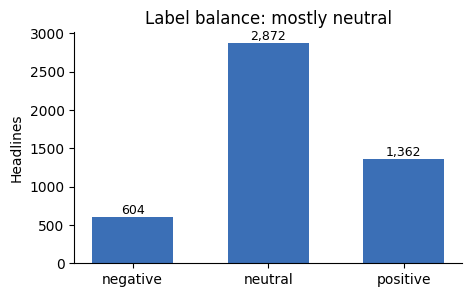

In [9]:
counts = df["sentiment"].value_counts().reindex(LABELS)
print((counts / counts.sum()).round(3))

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(counts.index, counts.values, color="#3b6fb6", width=0.6)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_title("Label balance: mostly neutral")
ax.set_ylabel("Headlines")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

            count  mean   std  min   25%   50%   75%   max
sentiment                                                 
negative    604.0  23.9   9.9  5.0  17.0  22.0  30.0  56.0
neutral    2872.0  22.2   9.8  2.0  15.0  21.0  28.0  81.0
positive   1362.0  24.7  10.1  5.0  17.0  23.0  31.0  57.0


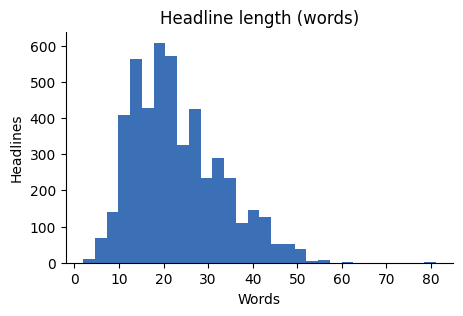

In [10]:
df["words"] = df["headline"].str.split().str.len()
print(df.groupby("sentiment")["words"].describe().round(1))

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(df["words"], bins=30, color="#3b6fb6")
ax.set_title("Headline length (words)")
ax.set_xlabel("Words")
ax.set_ylabel("Headlines")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [11]:
test = held_out_sample(df, n=300)  # fixed seed, stratified
test.to_csv("data/kaggle/test_sample.csv", index=False)
test["sentiment"].value_counts()

,count
sentiment,
neutral,178
positive,85
negative,37


## A3. Classifier evaluation: keyword baseline vs LLM

The LLM classifier is scored on the fixed 300-headline held-out sample with
a sentiment-only prompt. The live news chain uses a longer prompt that also
asks for relevance, but the Kaggle headlines have no target company, so that
instruction would only add noise here. Because LLM output varies between
runs (about 2 points of accuracy at n = 300), the score is the mean of
three runs.

In [12]:
from src.chains.kaggle import keyword_baseline, score, to_articles
from src.chains.news_chain import CLASSIFY_SENTIMENT_SYSTEM, classify

METRICS = ("accuracy", "macro_f1")
N_RUNS = 3  # LLM output varies run to run; report the mean, not one draw

base = score(test["sentiment"], test["headline"].map(keyword_baseline))
print("Keyword baseline:", {k: base[k] for k in METRICS})

articles = to_articles(test)
runs = []
for r in range(N_RUNS):
    labels = classify(articles, system=CLASSIFY_SENTIMENT_SYSTEM)
    pred = [
        labels.get(i, {}).get("sentiment", "neutral")
        for i in range(len(test))
    ]
    runs.append(score(test["sentiment"], pred))
    print(f"LLM run {r + 1}:", {k: runs[-1][k] for k in METRICS})

mean = {k: round(sum(s[k] for s in runs) / N_RUNS, 3) for k in METRICS}
print("LLM mean of", N_RUNS, "runs:", mean)

llm = runs[-1]  # last run's per-class report and confusion matrix
print(llm["report"])

Keyword baseline: {'accuracy': 0.647, 'macro_f1': 0.541}
LLM run 1: {'accuracy': 0.813, 'macro_f1': 0.822}
LLM run 2: {'accuracy': 0.787, 'macro_f1': 0.793}
LLM run 3: {'accuracy': 0.813, 'macro_f1': 0.815}
LLM mean of 3 runs: {'accuracy': 0.804, 'macro_f1': 0.81}
              precision    recall  f1-score   support

    negative       0.71      1.00      0.83        37
     neutral       0.96      0.72      0.82       178
    positive       0.69      0.93      0.79        85

    accuracy                           0.81       300
   macro avg       0.79      0.88      0.82       300
weighted avg       0.85      0.81      0.81       300



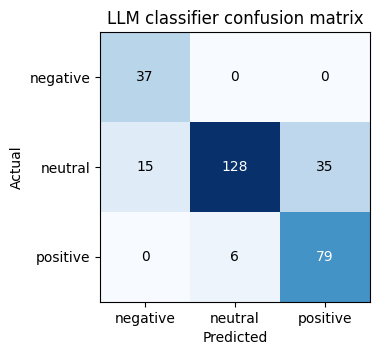

In [13]:
cm = llm["confusion"]

fig, ax = plt.subplots(figsize=(4, 3.5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), LABELS)
ax.set_yticks(range(3), LABELS)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
for i in range(3):
    for j in range(3):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, cm[i, j], ha="center", va="center", color=color)
ax.set_title("LLM classifier confusion matrix")
plt.show()

# Part B. Agent run

## Agent Design and Workflows

The agent is a LangGraph state graph (`src/graph.py`):

```
ticker -> plan -> route -> specialists -> synthesize -> evaluate --pass--> reflect -> memory
                                                            |                 ^
                                                            +--refine--> optimize
```

| Requirement | Where | Printed below |
|---|---|---|
| Plans research steps | `agents/planner.py` | B2 |
| Uses tools dynamically | `agents/toolkit.py`, `tools/` | B3 |
| Routing | `agents/router.py` | B4 |
| Prompt chaining | `chains/news_chain.py` | B5 |
| Evaluator-optimizer | `agents/evaluator.py` | B7 |
| Self-reflection | `agents/evaluator.py: reflect` | B9 |
| Learns across runs | `memory/store.py` | B10 |

This part runs the agent once on NVDA and prints the output of every step
from the run trace, then runs it a second time to show memory in use.
Memory is cleared first so B2 is a true first run.


## B1. Setup check: every tool returns data


In [14]:
print("Chunks indexed:", index_filings(TICKERS))
pd.DataFrame({t: quick_smoke(t) for t in TICKERS})

Chunks indexed: 566


,NVDA,JPM,XOM
get_price_history,ok,ok,ok
get_key_stats,ok,ok,ok
get_financials,ok,ok,ok
get_macro_snapshot,ok,ok,ok
get_news,ok,ok,ok


## B2. Research plan

The planner reads memory first. On the first run of a ticker there are no
notes; later runs show the lessons it used.

In [15]:
# Start from empty memory so the first run below is a true first run.
store.NOTES_PATH.unlink(missing_ok=True)
print("Lessons in memory:", len(store.load_notes()))


Lessons in memory: 0


In [16]:
TICKER = "NVDA"
notes_before = store.load_notes()

report, trace, state = run_agent(TICKER)

print("Sector:", state["sector"])
print("Hypothesis:", state["plan"].hypothesis)
show.plan_table(trace)

Sector: Technology
Hypothesis: Can Nvidia sustain its premium valuation given AI-driven growth against risks of customer concentration, export controls, and competitive pressure?


,id,task,tool,purpose,priority
0,1,"Gather market cap, P/E, P/B, margins, ROE, analyst price target and rating",get_key_stats,Establish current valuation and profitability baseline versus growth expectations,high
1,2,"Pull annual income statement, balance sheet, and cash flow data",get_financials,"Assess revenue growth trajectory, margin trends, and balance sheet strength to support AI capex cycle",high
2,3,"Analyze 5-year daily price history for returns, volatility, and beta vs SPY",get_price_history,Understand historical risk/return profile and how the stock behaves relative to the broader market,medium
3,4,"Retrieve latest CPI, Fed funds rate, 10-year yield, unemployment, and GDP data",get_macro_snapshot,Contextualize valuation sensitivity to interest rates and macro conditions affecting tech multiples,medium
4,5,Search recent news headlines on Nvidia,get_news,"Identify near-term catalysts such as earnings, product launches, export control updates, or competitive moves",high
5,6,Search 10-K Risk Factors for customer concentration and export control language,search_filings,Quantify dependency on hyperscaler customers and exposure to China export restrictions as key risk factors,high
6,7,Search 10-K MD&A for commentary on competitive landscape and gross margin drivers,search_filings,"Understand management's view on competitive threats from AMD, custom silicon, and supply chain constraints",medium


In [17]:
show.memory_read(trace)

No prior lessons: first run for this ticker and sector.


,lesson


## B3. Tool calls (dynamic tool use)

The plan, not the code, decides which tools run and with what query.
The three specialists run in parallel, so the log is grouped by the
specialist (`route`) that made each call.


In [18]:
show.tool_log(trace)

,route,tool,args,ok,rows,error
0,earnings,get_key_stats,{},True,14,None
1,earnings,get_financials,{},True,12,None
2,earnings,search_filings,{'query': 'Search 10-K Risk Factors for customer concentration and export control language'},True,3,None
3,earnings,search_filings,{'query': 'Search 10-K MD&A for commentary on competitive landscape and gross margin drivers'},True,3,None
4,market,get_price_history,{},True,7,None
5,market,get_macro_snapshot,{},True,5,None
6,news,get_news,{},True,100,None


## B4. Routing decisions

In [19]:
show.routing_table(trace)

,step_id,route,reason
0,1,earnings,"This task gathers valuation and profitability ratios, along with analyst targets and ratings, which fall under finan..."
1,2,earnings,"Pulling annual income statements, balance sheets, and cash flow data to assess revenue growth, margins, and financia..."
2,3,market,"This task analyzes five-year daily returns, volatility, and beta versus SPY, which are market performance and risk m..."
3,4,market,The task requests current macroeconomic indicators and interest-rate context that can influence market conditions an...
4,5,news,"This task asks for recent Nvidia headlines and near-term catalysts, so it belongs with the news analyst."
5,6,earnings,This task searches 10-K risk-factor disclosures for customer concentration and export-control language.
6,7,earnings,"This task searches 10-K MD&A for management commentary on competition, gross margin drivers, and supply chain constr..."


## B5. News prompt chain: output of each step

The digest's `net_sentiment` is not the model's opinion: the chain counts
the per-article labels from the classify step and applies majority rule
with a 15-point margin (`sentiment_counts` is printed with the summary).
Empty `figures` lists in the extract step are expected for headline-only
items; the extractor only reports numbers that appear in the text.


In [20]:
show.news_chain_steps(trace)


=== INGEST ===
{
 "n": 100,
 "sample": [
  "Nvidia takes stakes in Genesis AI, Pigment, and Entalpic in Paris push",
  "NVIDIA RTX Spark Game Ready for Dozens of AAA Titles at Launch, Including DLSS 5 and Anti-Cheat Support",
  "Nvidia Stock Has a Massive AI Tailwind. Here\u2019s the Bull Case",
  "nvidia-nvcomp-cu13 6.0.0.12",
  "TSMC Could Hit Its 2027 2nm Capacity Goals A Year Early As NVIDIA, AMD And Apple Pile On Orders For Latest Chipmaking Tech"
 ]
}

=== PREPROCESS ===
{
 "n_in": 100,
 "n_out": 91
}

=== CLASSIFY ===
{
 "0": {
  "id": 0,
  "topic": "m&a",
  "sentiment": "positive",
  "relevance": "high"
 },
 "1": {
  "id": 1,
  "topic": "product",
  "sentiment": "positive",
  "relevance": "high"
 },
 "2": {
  "id": 2,
  "topic": "other",
  "sentiment": "positive",
  "relevance": "high"
 },
 "3": {
  "id": 3,
  "topic": "product",
  "sentiment": "neutral",
  "relevance": "high"
 },
 "4": {
  "id": 4,
  "topic": "macro",
  "sentiment": "positive",
  "relevance": "high"
 }
}

===

## B6. Specialist findings

In [21]:
show.findings_table(trace)

,route,summary,key_figures,risks
0,market,"NVDA closed at $220.61, up 3.98% over the past month and 17.15% over the past year, with annualized volatility of 37...","[Last close: $220.61, 1-month return: 3.98%, 1-year return: 17.15%, Annualized volatility: 37.49%, Beta vs SPY: 2.12...","[High beta (2.13) means NVDA could see amplified downside in a broad market selloff, Elevated 10-year yield (5.24%, ..."
1,earnings,"NVIDIA trades at a $5.32T market cap with trailing P/E of 27.87x and forward P/E of 13.85x, reflecting expectations ...","[Market Cap: $5,322,481,598,464, Trailing P/E: 27.87x, Forward P/E: 13.85x, Price/Book: 23.24x, Profit Margin (TTM):...",[Customer concentration: 'A significant amount of our revenue stems from a limited number of partners and distributo...
2,news,"The supplied coverage is predominantly positive (61 positive versus 10 negative and 15 neutral items), reflecting co...","[AI infrastructure demand and capacity expansion remain supportive, with TSMC reportedly seeing strong orders for it...",[Microsoft’s Maia chips and broader moves toward custom silicon could reduce reliance on Nvidia among major customer...


## B7. Evaluator-optimizer loop

The evaluator (a different model family from the writer) scores the draft
1-5 on five criteria and lists critiques; the optimizer rewrites the draft
to address them. Every draft gets at least one revision
(`MIN_ITERATIONS = 1`), then the loop stops once the average reaches 4.0
or after three rounds. Iteration 0 is the first draft; iteration 1 is the
revised one.

In [22]:
show.evaluation_history(state)

,iteration,average,completeness,evidence,accuracy,balance,clarity
0,0,3.6,5,4,2,4,3
1,1,4.6,5,4,5,5,4


In [23]:
show.critiques(state)


Iteration 0 (avg 3.6):
  - Correct the central valuation claim: the $328.72 mean analyst price target is above, not below, NVDA’s $220.61 last close. The thesis, bear case, and conclusion all draw the wrong risk/reward inference from this comparison.
  - Do not compare market cap directly with a per-share price target. Compare the target with the share price, and reassess the claim that the stock has little room for upside.
  - Qualify the TSMC 2nm orders as reported, rather than presenting them as confirmed.
  - Separate the stated drivers of gross-margin compression from the 41% opex increase; the findings do not establish that all cited factors drove the operating- and net-margin declines.
  - Make the concluding stance more actionable for a portfolio manager by stating what would change the cautious view.

Iteration 1 (avg 4.6):
  - Reconcile the conflicting analyst-target context: the earnings finding says $328.72 is below the trading level implied by market cap, while the market

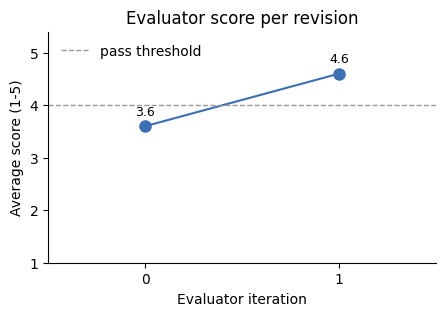

In [24]:
show.plot_scores(state)
plt.show()

## B8. Final report

In [25]:
display(show.report_markdown(report))

# NVDA research brief

**Thesis:** Nvidia's FY2026 results show extraordinary growth and a dominant AI infrastructure position. At \$220.61, shares trade below the \$328.72 analyst mean target, implying potential upside, but elevated trailing multiples (P/E 27.87x, P/B 23.24x), margin pressure from the Hopper-to-Blackwell transition and H20 charge, rising opex, and a sharp rise in the 10-year yield (5.24%) argue for selectivity rather than chasing near-term strength.

## Bull case
- Explosive growth: FY2026 revenue +65.5% YoY to \$215.94B, net income +64.7% to \$120.07B, diluted EPS \$4.90 vs \$2.94
- Exceptional profitability and capital efficiency: ROE 117.2%, operating margin ~60.4%, FCF of \$96.68B, minimal leverage (D/E 0.07x)
- Analyst mean target of \$328.72 sits well above the \$220.61 last close, implying meaningful upside per Strong Buy consensus (59 analysts)
- Forward P/E of 13.85x is well below trailing P/E (27.87x), implying consensus expects continued strong earnings growth
- Expanding AI ecosystem partnerships (Cisco networking/optical designs, reportedly strong TSMC 2nm capacity orders) and positive news skew (61 positive vs 10 negative vs 15 neutral)

## Bear case
- Trailing valuation remains rich (P/E 27.87x, P/B 23.24x), leaving limited room for error if growth decelerates even with the target above the current price
- Gross margin pressure from the Hopper-to-Blackwell transition and a \$4.5B H20 inventory charge, combined with a separate 41% YoY opex increase, weighed on operating margin (~60.4% vs 62.4%) and net margin (~55.6% vs 55.8%)
- Customer concentration and the rise of custom silicon (e.g., Microsoft Maia) threaten long-term reliance on Nvidia's GPUs
- China exposure is weakening amid export controls, regulatory scrutiny, and reported share losses to Huawei
- Macro headwinds: 10-year Treasury yield surged to 5.24% (up ~110bps YoY), high beta (2.13), and 37.49% annualized volatility raise downside sensitivity to rate-driven multiple compression

## Fundamentals
NVDA posted FY2026 revenue of \$215.94B (+65.5% YoY) and net income of \$120.07B (+64.7% YoY), with diluted EPS of \$4.90 versus \$2.94. Gross margin compressed due to the Hopper-to-Blackwell product transition and a \$4.5B H20 excess-inventory charge; separately, a 41% YoY rise in opex (compensation and infrastructure investment) contributed to operating margin slipping to ~60.4% from 62.4% and net margin to ~55.6% from 55.8%. Balance sheet strength is notable: total assets grew to \$206.8B, equity to \$157.3B, debt/equity fell to 0.07x, and cash stood at \$10.6B. Operating cash flow of \$102.72B and free cash flow of \$96.68B (after \$6.04B capex) underscore robust cash generation. Valuation metrics are elevated on a trailing basis (P/E 27.87x, P/B 23.24x), while the forward P/E of 13.85x and the \$328.72 analyst mean target (above the \$220.61 last close) suggest the market still expects strong growth to continue.

## News and catalysts
News flow is heavily positive (61 positive vs. 10 negative, 15 neutral), centered on AI infrastructure capacity (reportedly strong TSMC 2nm orders from Nvidia and other customers), ecosystem expansion (Cisco networking/optical designs for AI factories), product advances (DLSS 5, RTX Spark), and European AI investment plans. Counterweights include customer moves toward custom silicon (Microsoft Maia), reported share erosion to Huawei in China, and investor sensitivity to AI monetization evidence following an OpenAI revenue report that pressured chip stocks broadly. These catalysts and risks point to continued volatility tied to AI capex sentiment rather than fundamental deterioration.

## Market and macro
NVDA closed at \$220.61, up 3.98% over the past month and 17.15% over the past year, trading below its 50-day SMA (\$223.20) but above its 200-day SMA (\$202.69), indicating a near-term pullback within a longer-term uptrend. The stock's high beta (2.13) and elevated annualized volatility (37.49%) imply amplified sensitivity to broad market swings. Macro conditions show CPI at 3.72% YoY, Fed funds easing to 3.75% from 4.22%, but the 10-year Treasury yield rising sharply to 5.24% from 4.14%—a headwind for high-multiple growth equities via higher discount rates—alongside falling unemployment (4.2%) and modest real GDP growth (~2.19% YoY).

## Conclusion
Nvidia's fundamentals remain among the strongest in large-cap tech, with exceptional growth, margins, and cash generation. The \$328.72 analyst mean target above the \$220.61 last close signals potential upside, but rich trailing multiples, margin pressure from the Blackwell transition, and a sharp rise in the 10-year yield argue against adding aggressively into near-term strength. A pullback toward the 200-day SMA (\$202.69) alongside stabilizing gross margins and continued confirmation of sustained hyperscaler capex (rather than signs of AI-monetization doubt) would offer a more attractive entry; conversely, further opex-driven margin erosion or evidence of accelerated custom-silicon substitution by major customers would warrant greater caution. This is analysis, not investment advice.

*Analysis only; not investment advice.*

## B9. Reflection (self-assessment of output and process)

In [26]:
show.reflection_view(state)

{'weakest_section': "Fundamentals/Valuation framing (feeding into Conclusion) — the brief treats the $328.72 analyst mean target as straightforward 'upside' evidence without noting the target's date/dispersion, and labels trailing multiples 'rich' without any peer (AMD, custom-silicon) or historical multiple comparison to substantiate that characterization.",
 'unsupported_claims': ["'$328.72 analyst mean target... implying meaningful upside' — no data on when the target was set or its dispersion/range across the 59 analysts, so it may be stale relative to the current price run-up",
  "'China exposure is weakening' — based on a single news report of Huawei share gains, extrapolated into a definitive trend",
  "'Rich valuation (P/E 27.87x, P/B 23.24x)' framed as a bear point with no peer/sector multiple comparison to establish relative richness",
  "'Expanding AI ecosystem partnerships... reportedly strong TSMC 2nm capacity orders' presented as a bull catalyst despite being a third-part

## B10. Memory: what this run taught the agent

New lessons written to `memory/notes.json`, then a second run on the same
ticker to show the planner reading them.

In [27]:
show.memory_diff(trace)

,ticker,sector,date,lesson
0,NVDA,Technology,2026-10-14,"For AI/semiconductor mega-caps, always pull segment-level revenue (data center/gaming/auto) since blended margins ca..."
1,NVDA,Technology,2026-10-14,"Before calling a valuation 'rich' or 'cheap,' pull at least one peer's key stats for multiple comparison rather than..."
2,NVDA,Technology,2026-10-14,"Treat analyst mean price targets cautiously — capture the target date and dispersion, since targets can lag fast-mov..."
3,NVDA,Technology,2026-10-14,"When customer concentration or competitive risk is cited qualitatively, search filings for the actual quantitative d..."
4,NVDA,Technology,2026-10-14,"Macro-to-equity linkages (e.g., rising 10Y yield) should be paired with a concrete sensitivity or multiple-compressi..."


In [28]:
report2, trace2, state2 = run_agent(TICKER)
print("Lessons the planner read on run 2:")
display(show.memory_read(trace2))
print("Run 1 steps:", [s.tool for s in state["plan"].steps])
print("Run 2 steps:", [s.tool for s in state2["plan"].steps])
print("Run 1 final score:", state["history"][-1]["average"],
      "| Run 2 final score:", state2["history"][-1]["average"])

Lessons the planner read on run 2:


,ticker,sector,date,lesson
0,NVDA,Technology,2026-10-14,"For AI/semiconductor mega-caps, always pull segment-level revenue (data center/gaming/auto) since blended margins ca..."
1,NVDA,Technology,2026-10-14,"Before calling a valuation 'rich' or 'cheap,' pull at least one peer's key stats for multiple comparison rather than..."
2,NVDA,Technology,2026-10-14,"Treat analyst mean price targets cautiously — capture the target date and dispersion, since targets can lag fast-mov..."
3,NVDA,Technology,2026-10-14,"When customer concentration or competitive risk is cited qualitatively, search filings for the actual quantitative d..."
4,NVDA,Technology,2026-10-14,"Macro-to-equity linkages (e.g., rising 10Y yield) should be paired with a concrete sensitivity or multiple-compressi..."


Run 1 steps: ['get_key_stats', 'get_financials', 'get_price_history', 'get_macro_snapshot', 'get_news', 'search_filings', 'search_filings']
Run 2 steps: ['get_financials', 'get_key_stats', 'get_key_stats', 'search_filings', 'search_filings', 'get_price_history', 'get_macro_snapshot', 'get_news']
Run 1 final score: 4.6 | Run 2 final score: 4.4


# Part C. Evaluation

## Evaluation and Iteration

Part B showed one evaluator-optimizer loop. This part measures the agent
against alternatives, all scored with the same rubric and the same
findings so the comparison is fair.

The numeric spot-check (`unsupported_*`) counts figures in a brief that
appear in no finding. A figure the writer labels as calculated (for
example "a calculated ~65% increase") is exempt: the evaluator asks for
that label, and such figures are arithmetic on the findings rather than
claims needing their own source. The baseline never sees the findings,
so its evidence and accuracy scores are structurally low; the comparison
measures whether tools and the loop produce a grounded brief.


## C1. Three comparisons

Three comparisons, all scored with the same rubric and the same findings:

1. **Baseline vs agent:** a single prompt with no tools, no plan, no loop.
2. **Numeric spot-check:** figures in each brief that appear in no finding.
3. **Memory on vs off:** the same ticker with memory disabled.

In [29]:
rows = []
for t in TICKERS:
    rep, tr, st = run_agent(t)
    base = baseline_brief(t)
    base_score = score_against_findings(base, st["findings"])
    findings = st["findings"]
    rows.append(
        {
            "ticker": t,
            "baseline_avg": base_score["average"],
            "agent_first_draft": st["history"][0]["average"],
            "agent_final": st["history"][-1]["average"],
            "iterations": len(st["history"]),
            "tool_success": tool_success_rate(tr),
            "unsupported_baseline": len(unsupported_figures(base, findings)),
            "unsupported_agent": len(
                unsupported_figures(st["draft"], findings)
            ),
        }
    )
results = pd.DataFrame(rows)
results

,ticker,baseline_avg,agent_first_draft,agent_final,iterations,tool_success,unsupported_baseline,unsupported_agent
0,NVDA,2.2,4.4,4.4,2,1.0,4,1
1,JPM,1.8,4.6,4.4,2,1.0,3,5
2,XOM,2.0,4.2,4.6,2,1.0,14,3


In [33]:
from pathlib import Path

from IPython.display import Markdown, display

from src.agents.schemas import Draft
from src.agents.synthesizer import render
from src.trace import RUNS_DIR, RunTrace


def final_draft(trace: RunTrace) -> Draft:
    """The last revision if the optimizer ran, else the first draft."""
    revisions = trace.select("optimizer", "revision")
    event = revisions[-1] if revisions else trace.select("synthesizer")[-1]
    return Draft(**event.output)


for ticker in ("JPM", "XOM"):
    latest = sorted(RUNS_DIR.glob(f"{ticker}_*.json"))[-1]
    draft = final_draft(RunTrace.load(latest))
    display(Markdown(f"### {ticker} research brief ({latest.name})"))
    display(show.report_markdown(render(draft)))

### JPM research brief (JPM_20261014_182034.json)

# JPM research brief

**Thesis:** JPMorgan grew FY2025 revenue to \$181.8B with 18% ROE and 34.6% net margin, trading at 13.97x trailing P/E and 2.52x P/B versus a \$372.73 analyst mean target against a \$334.05 close. A Q3 EPS miss, reduced buyback, markedly more negative operating cash flow (-\$147.8B), and a steepening yield curve (10Y 5.24% vs Fed funds 3.75%) create near-term uncertainty despite a longer-term uptrend above the 200-day SMA.

## Bull case
- Revenue grew to \$181.8B (from \$169.4B) with 18.0% ROE and 34.6% net margin, reflecting strong core profitability
- Markets & Securities Services revenue up 19% to \$41.3B and Investment Banking up 6% to \$10.2B show diversified fee growth
- Valuation at 13.97x trailing / 13.12x forward P/E sits below Buy consensus (22 analysts) with a \$372.73 mean target, ~12% above last close
- Card spending resilience (\$539B) and improving credit quality, with criticized real estate exposure declining from \$12.4B to \$11.7B
- Beta of 0.873 indicates lower systematic risk than the broad market, with price holding above its 200-day SMA (\$322.22) in a longer-term uptrend

## Bear case
- Q3 EPS missed expectations (\$5.57 vs \$5.90 consensus), alongside a reduced buyback program, raising questions about near-term capital return and earnings momentum
- Operating/free cash flow became substantially more negative (-\$147.8B in 2025 vs -\$42.0B in 2024); filings attribute this to balance sheet growth but do not fully explain the magnitude of the change
- Steepening yield curve (10Y at 5.24% vs Fed funds down to 3.75%) could compress net interest margins despite NII growth to \$95.9B
- Dimon warned of rising borrowing costs spilling into corporate credit and a tenfold increase in AI-related cyber threats, flagging operational and macro credit risks
- Stock is down 5.23% over the past month and trading below its 50-day SMA (\$348.90), signaling near-term bearish momentum with 22.23% annualized volatility

## Fundamentals
FY2025 revenue rose to \$181.85B from \$169.44B, though net income slipped slightly to \$57.05B from \$58.47B, with diluted EPS up to \$20.02 from \$19.75. ROE stands at 18.0% and net margin at 34.6%, reflecting strong core profitability. Total assets grew to \$4.425T and equity to \$362.44B, but debt-to-equity rose to 1.379x and operating cash flow was -\$147.78B, substantially more negative than -\$42.01B in FY2024; available filings associate this with balance sheet growth but do not fully detail the drivers. Segment strength was led by Markets & Securities Services (+19% to \$41.3B) and Investment Banking (+6% to \$10.2B). The stock trades at 13.97x trailing P/E, 13.12x forward P/E, and 2.52x P/B, below the \$372.73 analyst mean target against a \$334.05 close.

## News and catalysts
Sentiment is roughly balanced (28 neutral, 21 positive, 17 negative items). The bank raised its income outlook despite weaker bond trading, and card spending/credit metrics (\$539B spend, improving credit) support a resilient consumer narrative, alongside positive AI/technology positioning. Offsetting this, JPMorgan posted a rare Q3 EPS miss (\$5.57 vs \$5.90 expected) with a reduced buyback, and Jamie Dimon flagged risks including rising borrowing costs potentially spilling into corporate credit and a tenfold increase in AI-related cybersecurity threats.

## Market and macro
JPM closed at \$334.05, down 5.23% over the past month but up 8.47% over the trailing year, with 22.23% annualized volatility and a beta of 0.873 versus the S&P 500. The stock trades below its 50-day SMA (\$348.90) but above its 200-day SMA (\$322.22), suggesting a near-term pullback within a longer-term uptrend. Macro conditions show the Fed funds rate falling to 3.75% while the 10-year Treasury yield rose sharply to 5.24%, a steepening dynamic that could pressure bank margins. CPI remains elevated at 3.72% YoY, unemployment eased to 4.2%, and real GDP grew 2.19% YoY, pointing to a resilient but inflation-pressured economy.

## Conclusion
JPMorgan's fundamentals remain solid—strong ROE, margin, and segment fee growth—at multiples below the analyst consensus target, but near-term risks (Q3 miss, reduced buyback, sharply more negative operating cash flow, and a steepening yield curve) warrant caution. A more constructive near-term stance would require evidence that cash flow normalizes, buybacks resume, yield-curve steepening stabilizes without NIM compression, and credit metrics (including real estate criticized exposure) continue improving; conversely, further buyback cuts, a sustained break below the 200-day SMA, or escalating credit/cyber risk commentary from management would reinforce caution. This is analysis, not investment advice.

*Analysis only; not investment advice.*

### XOM research brief (XOM_20261014_182335.json)

# XOM research brief

**Thesis:** XOM's 57.79% 1-year return and uptrend above 50/200-day SMAs show strong momentum, but at ~\$177 the stock sits above the \$173.64 analyst mean target while FY2025 revenue, net income, and FCF all declined YoY. Low beta (0.385) and a conservative FY2024 balance sheet (D/E 0.158) support defensive positioning, but rising 10-year yields (5.24%) and a shrinking cash balance argue for disciplined entry. Catalysts (Venezuela, LNG, carbon capture) are constructive but speculative.

## Bull case
- Strong technical uptrend: +4.59% over 1-month and +57.79% over 1-year, well above 50-day (\$162.75) and 200-day (\$151.16) SMAs
- Low beta (0.385) versus SPY offers portfolio diversification and reduced market-correlated volatility
- Conservative FY2024 balance sheet (debt-to-equity 0.158, total debt \$41.71B) provides financial flexibility for capex and dividends (2.37% yield)
- Multiple growth catalysts: potential Venezuela re-entry, raised 2030 LNG target to 50 million tons annually (2x current volume), and \$5B Texas carbon-capture project approval
- Forward P/E (15.26) is below trailing P/E (22.81), consistent with analyst expectations for higher near-term earnings, though this alone doesn't confirm a sustained recovery

## Bear case
- FY2025 financials weakened YoY: revenue fell to \$323.9B from \$339.2B, net income to \$28.84B from \$33.68B, and free cash flow to \$23.61B from \$30.72B
- Cash balance dropped sharply from \$23.03B to \$10.68B while capex rose to \$28.36B (cash capex \$29.0B), raising liquidity questions if commodity prices soften
- Stock price (\$177.10) already exceeds the analyst mean target (\$173.64), suggesting limited near-term upside per consensus
- Rising 10-year Treasury yield to 5.24% increases discount rates and cost of capital, a headwind for capital-intensive energy valuations
- Operational and legal overhangs: Joliet refinery shutdown disrupting Midwest diesel supply, a separate power-outage investigation at the same refinery, unresolved Supreme Court climate litigation exposure, and a board-seat dispute creating governance friction

## Fundamentals
XOM trades at a trailing P/E of 22.81 (forward 15.26), P/B of 2.81, with TTM net margin of 9.07% and ROE of 12.58%. FY2025 revenue declined to \$323.9B from \$339.2B, net income to \$28.84B (\$6.70 diluted EPS) from \$33.68B (\$7.84 EPS), and free cash flow to \$23.61B from \$30.72B, even as capex rose to \$28.36B driven by Permian/Pioneer integration (upstream capex \$24.7B, up \$4.4B YoY). FY2024 debt-to-equity stood at 0.158 with total debt of \$41.71B against \$263.7B equity (FY2025 equity: \$259.4B). Cash fell sharply from \$23.03B (FY2024) to \$10.68B (FY2025). 2026 planned capex is \$27B-\$29B with \$8.5B in firm commitments.

## News and catalysts
Sentiment is net positive, driven by Exxon's prospective return to Venezuela after nearly two decades, a raised 2030 LNG sales target of 50 million tons (doubling current volume), and Texas approval for a \$5B carbon-capture project. Exxon and Suncor are also seeking to block climate lawsuits at the Supreme Court, which could reduce future litigation exposure. Offsetting these, the company shut down its Joliet refinery (disrupting Midwest diesel supply) and separately faces a power-outage investigation at the same facility, unresolved Supreme Court climate-law exposure, and a governance dispute involving a shale magnate's board-seat challenge. The CFO also flagged hidden risks tied to a potential oil supply shock.

## Market and macro
XOM closed at \$177.10, up 4.59% over one month and 57.79% over one year, trading well above its 50-day (\$162.75) and 200-day (\$151.16) SMAs in a confirmed uptrend. Annualized volatility is 25.9% with a low beta of 0.385 versus SPY. Macro conditions show CPI at 3.72% YoY (above Fed target), Fed funds rate easing to 3.75% from 4.22%, yet the 10-year Treasury yield rising sharply to 5.24% from 4.14% — a divergence that may reflect market concern over longer-term inflation or fiscal risk. GDP growth is 2.19% YoY and unemployment eased to 4.2% from 4.4%.

## Conclusion
XOM shows strong momentum and a defensive profile but trades above consensus fair value while FY2025 fundamentals softened. Entry view: favor existing holders or accumulation on pullbacks toward or below the \$173.64 analyst target rather than chasing strength here. Watch: 10-year yield trajectory (cost of capital), cash balance trend versus capex, commodity price direction, and resolution of Supreme Court climate litigation and the board-seat dispute. Catalysts (Venezuela, LNG expansion, carbon capture) offer upside optionality but remain unconfirmed. Analysis only; not investment advice.

*Analysis only; not investment advice.*

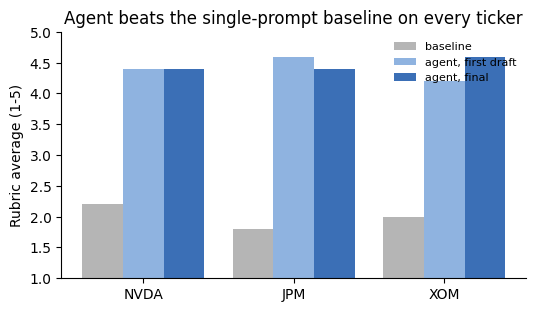

In [30]:
fig, ax = plt.subplots(figsize=(6, 3.2))
x = list(range(len(results)))
w = 0.27
series = [
    ("baseline_avg", "baseline", "#b5b5b5", -w),
    ("agent_first_draft", "agent, first draft", "#8fb3e0", 0),
    ("agent_final", "agent, final", "#3b6fb6", w),
]
for col, label, color, offset in series:
    ax.bar([i + offset for i in x], results[col], w, label=label, color=color)
ax.set_xticks(x, results["ticker"])
ax.set_ylim(1, 5)
ax.set_ylabel("Rubric average (1-5)")
ax.set_title("Agent beats the single-prompt baseline on every ticker")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.show()

In [31]:
_, tr_off, st_off = run_agent(TICKER, use_memory=False)
_, tr_on, st_on = run_agent(TICKER, use_memory=True)
pd.DataFrame([
    {"memory": "off", "plan_steps": len(st_off["plan"].steps),
     "notes_read": len(tr_off.select("memory", "read")[0].output),
     "final_score": st_off["history"][-1]["average"]},
    {"memory": "on", "plan_steps": len(st_on["plan"].steps),
     "notes_read": len(tr_on.select("memory", "read")[0].output),
     "final_score": st_on["history"][-1]["average"]},
])

,memory,plan_steps,notes_read,final_score
0,off,7,0,4.4
1,on,8,8,4.4


In [32]:
show.timing_table(trace)

,seconds
step,
evaluator,19.3
optimizer,34.9
planner,8.4
reflection,25.9
router,18.0
specialist,200.6
specialists,169.9
synthesizer,18.9


## C2. Limitations

- Figures come from free data sources (`yfinance` is unofficial; NewsAPI
  caps at 100 articles) and are cached, so a run reflects the cache date.
- The evaluator is an LLM and its scores vary by about 0.2 between runs.
- The agent has no view of future events, and the brief is analysis only,
  not investment advice.


## Summary

EquityAgent is an autonomous investment research agent that accepts a stock ticker, develops a research plan, executes six data tools, and processes news through a five-step prompt chain. It routes tasks to specialized earnings, news, and market agents, generates a research brief, and uses a second model family to evaluate and revise the output. The agent then reflects on its performance and stores lessons that inform future research plans. Each stage is documented through execution traces.

### Results

| Comparison | Result |
|---|---|
| **Sentiment classification (A3)** | LLM achieved 0.80 accuracy and 0.81 macro-F1 across three runs on 300 held-out Kaggle headlines, outperforming the keyword baseline (0.65 / 0.54). |
| **Evaluator-optimizer (B7, NVDA)** | Quality score improved from 3.6 to 4.6 after one revision. |
| **Agent vs. single-prompt baseline (C1)** | Agent scored 4.4 / 4.4 / 4.6 versus baseline scores of 2.2 / 1.8 / 2.0 for NVDA, JPM, and XOM, respectively. |
| **Unsupported figures (C1)** | Decreased from 4 to 1 for NVDA and 14 to 3 for XOM, but increased from 3 to 5 for JPM. |
| **Tool reliability (C1)** | 100% of tool calls succeeded across all three tickers. |
| **Memory ablation (C1, NVDA)** | Scores remained unchanged at 4.4, although memory expanded the research plan from 7 to 8 steps using 8 retrieved lessons. |
| **Parallel execution (C1)** | Wall-clock time decreased from 201 to 170 seconds, a 15% reduction relative to summed execution time. |

### Implementation of Agentic Requirements

- **Planning:** Generated a prioritized seven-step research plan addressing NVDA's premium valuation, customer concentration, export restrictions, and competition. A subsequent run incorporated prior lessons and produced a revised eight-step plan.
- **Dynamic tool use:** Research plans determined tool selection and query parameters. For example, `search_filings` executed separate queries covering customer concentration, export controls, competition, and gross-margin drivers.
- **Task routing:** Assigned four research steps to the earnings specialist, one to news, and two to market analysis, with explicit routing justifications.
- **Prompt chaining:** Filtered 100 headlines into 86 relevant articles and generated a sentiment digest containing 61 positive, 15 neutral, and 10 negative headlines. Sentiment reflects classified headline counts rather than an overall model opinion.
- **Evaluation and iteration:** Identified and corrected an invalid comparison between a per-share analyst price target and market capitalization. Every draft undergoes at least one revision, with evaluation ending when the score reaches 4.0 or after three rounds.
- **Self-reflection:** Identified the weakest research section, unsupported claims, and missing data, producing five reusable lessons.
- **Cross-run learning:** Used file-backed memory ranked by ticker, sector, and general relevance. Both the subsequent research run and memory-enabled ablation retrieved prior lessons.

### Limitations and Interpretation

The results demonstrate stronger evidence grounding but require several qualifications. The single-prompt baseline does not receive the agent's research findings, making its lower evidence and accuracy scores partly attributable to unequal information access rather than writing quality alone.

JPM's unsupported figure count increased because calculated financial ratios were not explicitly identified as derived values. Although memory influenced subsequent research planning, it did not improve the measured quality score. Parallel execution achieved a modest 15% time reduction because the news specialist remained the primary bottleneck, requiring approximately 11 sequential LLM calls. Evaluator scores also fluctuated by approximately 0.2 points across identical runs, indicating some measurement variability.

### Next Steps

Future improvements will focus on parallelizing news classification and extraction batches, adding peer-comparison and segment-level revenue tools to address recurring data gaps, and eliminating duplicate research steps based on tool-query combinations. Expanding baseline evaluations across additional tickers and dates will also help assess generalizability, evaluator consistency, and the agent's performance under different market conditions.
